#**CAR SALES ANALYSISE**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings


In [3]:
#Load the car sales dataset from a CSV file
car=pd.read_csv("../data/india_car_sales_22000_rows.csv")

In [23]:
#Display the first five rows of the dataset
car.head()


,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine_CC,Mileage_kmpl,...,Color,Body_Type,Seats,Insurance_Valid,Service_History,Registration_State,Selling_Price_INR,Car_Age,Selling_Price_Lakh,Mileage_Category
0,CAR102317,Renault,Kwid,2025,71964.0,Diesel,Manual,First Owner,1497.0,14.6,...,Silver,SUV,5,Yes,Full,WB,1403457.0,1,14.03457,Medium
1,CAR102346,Honda,City,2014,NaN,Petrol,AMT,Second Owner,1497.0,16.3,...,Black,SUV,5,Yes,Partial,MP,448389.0,12,4.48389,High
2,CAR107698,Maruti Suzuki,Swift,2017,95640.0,Petrol,AMT,First Owner,2755.0,15.5,...,White,Hatchback,4,Yes,Full,MP,577683.0,9,5.77683,High
3,CAR104583,Kia,Seltos,2024,3000.0,Diesel,CVT,First Owner,1197.0,20.0,...,Grey,SUV,5,Yes,NaN,KA,1542317.0,2,15.42317,High
4,CAR108321,Hyundai,i20,2014,112355.0,Diesel,Manual,Second Owner,1197.0,18.9,...,Blue,Sedan,7,Yes,NaN,KL,120318.0,12,1.20318,High


In [4]:
# Display the last five rows of the dataset
car.tail()

,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine_CC,Mileage_kmpl,City,Color,Body_Type,Seats,Insurance_Valid,Service_History,Registration_State,Selling_Price_INR
15849,SYN003850,Renault,Kiger,1973,NaN,CNG,Manual,First Owner,1623.464184,16.875691,Kolkata,Brown,MUV,5.0,SYN003850,Partial,SYN003850,7.845327e+05
15850,SYN003851,Skoda,Kushaq,2010,82260.446480,Petrol,CVT,First Owner,2326.113775,20.450707,Ahmedabad,Red,Sedan,7.0,SYN003851,Full,SYN003851,NaN
15851,SYN003852,Volkswagen,Taigun,1979,27397.950126,Petrol,CVT,First Owner,2503.358177,18.244888,Pune,White,Sedan,7.0,SYN003852,Partial,SYN003852,1.365233e+06
15852,SYN003853,Renault,Kiger,1991,88369.025984,Petrol,Manual,Third Owner,2708.499825,24.101163,Ahmedabad,Red,SUV,7.0,SYN003853,Partial,SYN003853,8.526522e+05
15853,SYN003854,Nissan,Magnite,1990,65590.644500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
# Display all column names in the dataset
car.columns

Index(['Car_ID', 'Brand', 'Model', 'Year', 'Kilometers_Driven', 'Fuel_Type',
       'Transmission', 'Owner_Type', 'Engine_CC', 'Mileage_kmpl', 'City',
       'Color', 'Body_Type', 'Seats', 'Insurance_Valid', 'Service_History',
       'Registration_State', 'Selling_Price_INR', 'Car_Age',
       'Selling_Price_Lakh', 'Mileage_Category'],
      dtype='object')

In [20]:
#show the columns and rows
car.shape


(22000, 21)

In [21]:
# Count missing values in each column
car.isnull().sum()

,0
Car_ID,0
Brand,0
Model,264
Year,0
Kilometers_Driven,240
Fuel_Type,187
Transmission,266
Owner_Type,0
Engine_CC,228
Mileage_kmpl,335


In [8]:
# Check the data types of all columns
car.dtypes

,0
Car_ID,object
Brand,object
Model,object
Year,int64
Kilometers_Driven,float64
Fuel_Type,object
Transmission,object
Owner_Type,object
Engine_CC,float64
Mileage_kmpl,float64


In [9]:
# Generate descriptive statistics for numerical columns
car.describe()

,Year,Kilometers_Driven,Engine_CC,Mileage_kmpl,Seats,Selling_Price_INR
count,15854.000000,15690.000000,15690.000000,15604.000000,15853.000000,1.575800e+04
mean,2018.441214,89077.368882,1643.193923,18.063056,5.591245,8.350549e+05
std,29.114019,33330.199757,582.721975,3.953321,1.008270,3.909586e+05
min,1912.000000,2857.864060,759.065153,6.685111,4.000000,9.507325e+04
25%,2014.000000,65998.047819,1197.000000,15.368413,5.000000,5.279668e+05
50%,2018.000000,88666.392931,1498.000000,18.100000,5.000000,8.329375e+05
75%,2023.000000,111613.895434,2198.000000,20.727361,7.000000,1.131841e+06
max,2125.000000,220000.000000,2891.858750,32.197460,8.000000,2.006825e+06


In [10]:
# Count the number of unique values in each column
car.nunique()

,0
Car_ID,15645
Brand,14
Model,54
Year,214
Kilometers_Driven,14901
Fuel_Type,5
Transmission,5
Owner_Type,4
Engine_CC,3821
Mileage_kmpl,4024


In [11]:
# Display all unique fuel types in the dataset
car['Fuel_Type'].unique()

array(['Diesel', 'Petrol', 'Hybrid', 'CNG', 'Electric', nan], dtype=object)

# **Univariate Analysis**

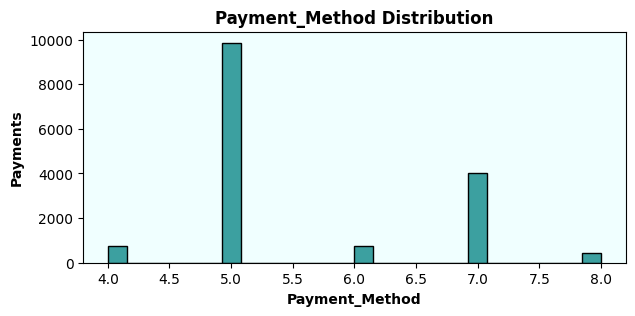

In [12]:
 # Plot the distribution of payment methods
plt.figure(figsize=(7,3))
sns.histplot(car['Seats'],color='teal').axes.set_facecolor("azure")
plt.title('Payment_Method Distribution',fontweight='bold')
plt.xlabel('Payment_Method',color='k',fontsize=10,fontweight='bold')
plt.ylabel('Payments',fontweight='bold')
plt.show()

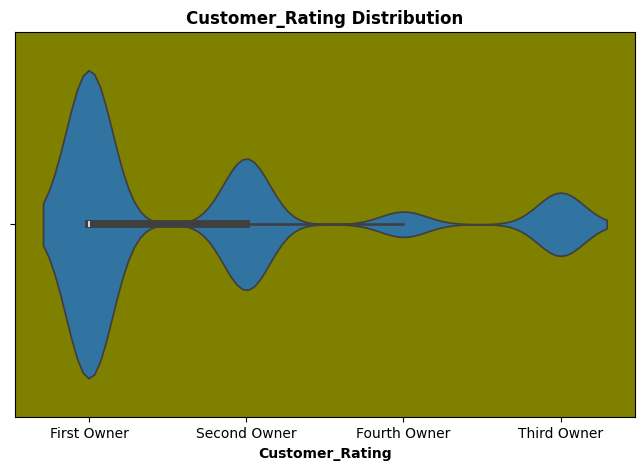

In [13]:
# 2. Shows the number of cars by owner type.
plt.figure(figsize=(8,5))
sns.violinplot(data=car,x='Owner_Type').axes.set_facecolor('olive')
plt.title("Customer_Rating Distribution",fontweight='bold')
plt.xlabel("Customer_Rating",fontweight='bold')
plt.show()

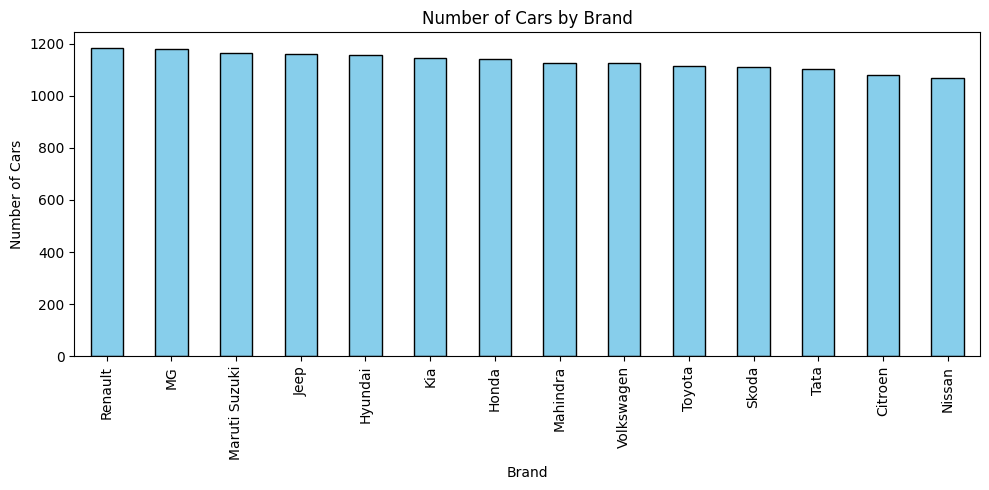

In [14]:
# 3. Displays the number of cars for each brand.
plt.figure(figsize=(10, 5))
car["Brand"].value_counts().plot(kind="bar",edgecolor="black",color="skyblue")
plt.title("Number of Cars by Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Cars")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

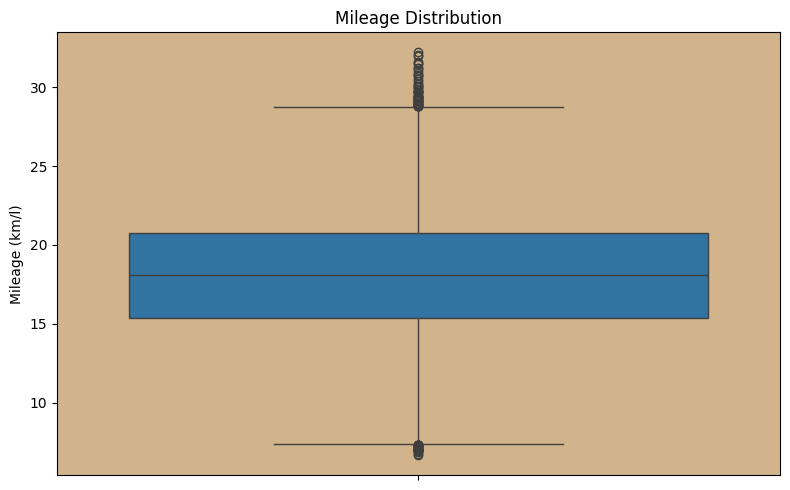

In [15]:
# 4. Shows mileage distribution and potential outliers.
plt.figure(figsize=(8, 5))
sns.boxplot(data=car, y="Mileage_kmpl").axes.set_facecolor("Tan")
plt.title("Mileage Distribution")
plt.ylabel("Mileage (km/l)")
plt.tight_layout()
plt.show()


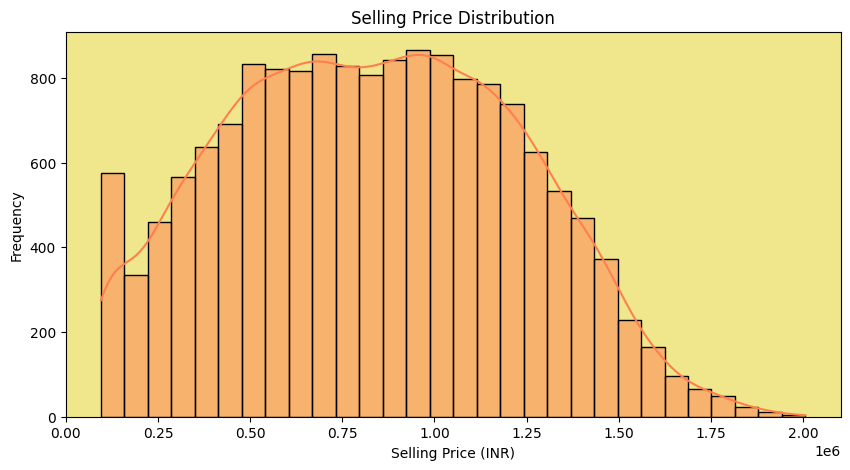

In [16]:
#  Displays the distribution of car selling prices.
plt.figure(figsize=(10, 5))
sns.histplot(data=car,x="Selling_Price_INR",bins=30,kde=True,color="coral").axes.set_facecolor("khaki")
plt.title("Selling Price Distribution")
plt.xlabel("Selling Price (INR)")
plt.ylabel("Frequency")
plt.show()


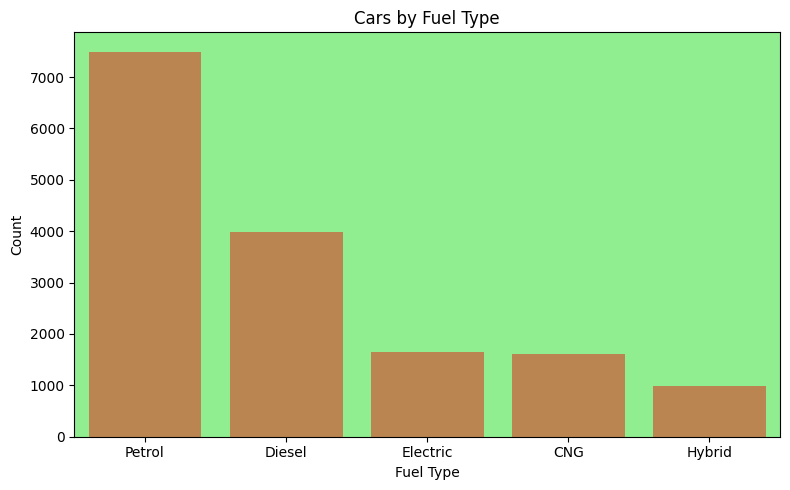

In [17]:
# 6. Compares the number of cars by fuel type.
plt.figure(figsize=(8, 5))
sns.countplot(data=car,x="Fuel_Type",color='peru',order=car["Fuel_Type"].value_counts().index).axes.set_facecolor("lightgreen")
plt.title("Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


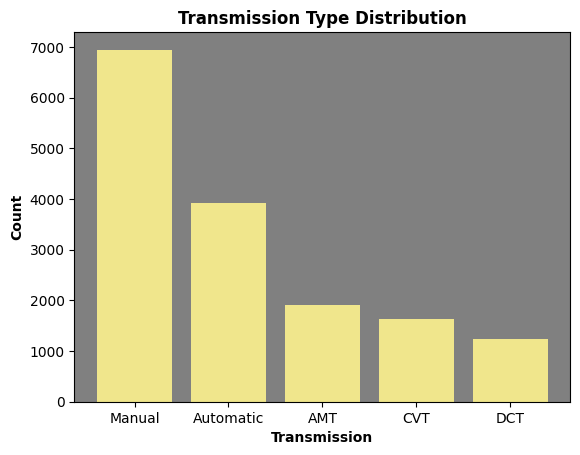

In [18]:
#  Compares the number of cars by transmission type.
Transmission = car['Transmission'].value_counts()
plt.bar(x=Transmission.index, height=Transmission.values, color='khaki')
plt.title("Transmission Type Distribution", fontweight='bold')
plt.xlabel("Transmission", fontweight='bold')
plt.ylabel("Count", fontweight='bold')
plt.gca().set_facecolor('gray')
plt.xticks(rotation=0)
plt.show()

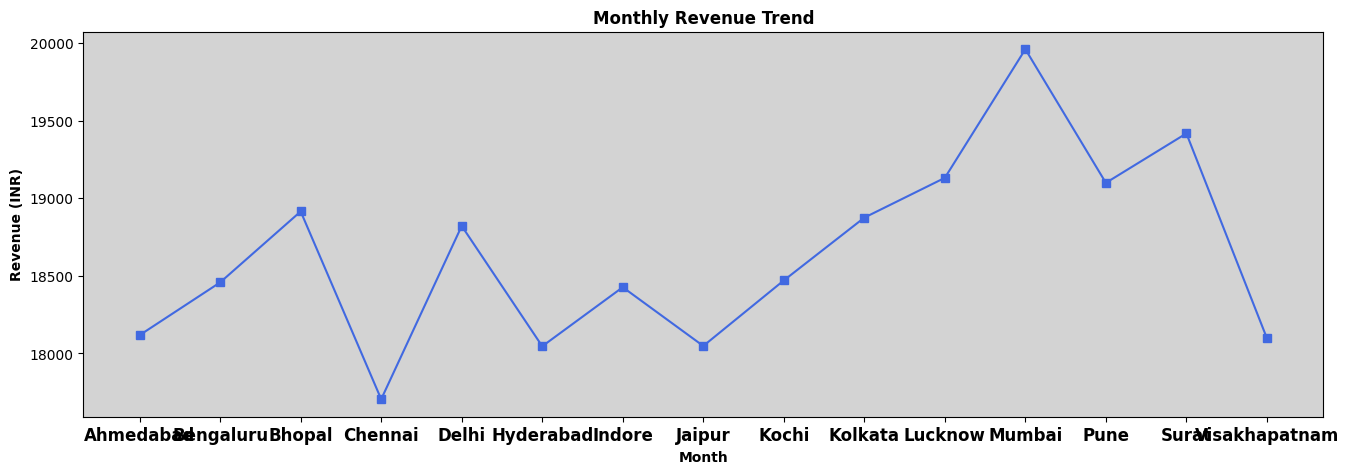

In [19]:
# 8. Shows total mileage values across different cities.
plt.figure(figsize=(16,5))
monthly_revenue = car.groupby('City')['Mileage_kmpl'].sum()
plt.plot(monthly_revenue.index,monthly_revenue.values,marker='s',color='royalblue')
plt.title("Monthly Revenue Trend",fontweight='bold')
plt.xlabel("Month",fontweight='bold')
plt.ylabel("Revenue (INR)",fontweight='bold')
plt.gca().set_facecolor('lightgray')
plt.xticks(fontweight='bold', fontsize=12)
plt.show()

#**Bivariate Analysis**

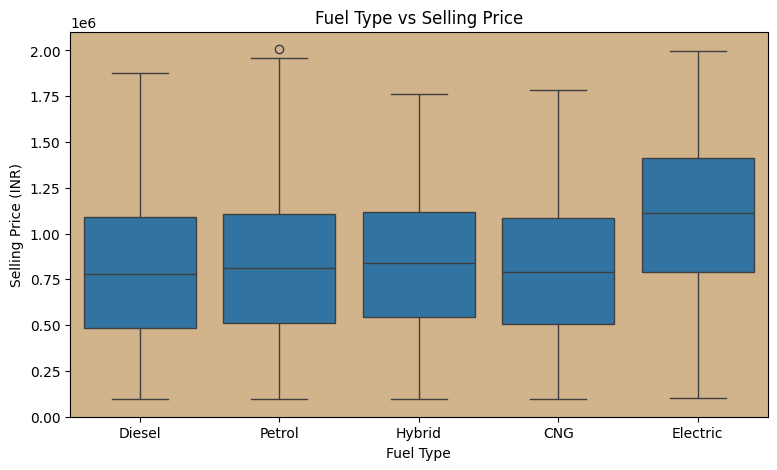

In [20]:
# Compares selling prices across fuel types.
plt.figure(figsize=(9, 5))
sns.boxplot(data=car,x="Fuel_Type",y="Selling_Price_INR").axes.set_facecolor("tan")
plt.title("Fuel Type vs Selling Price")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (INR)")
plt.show()

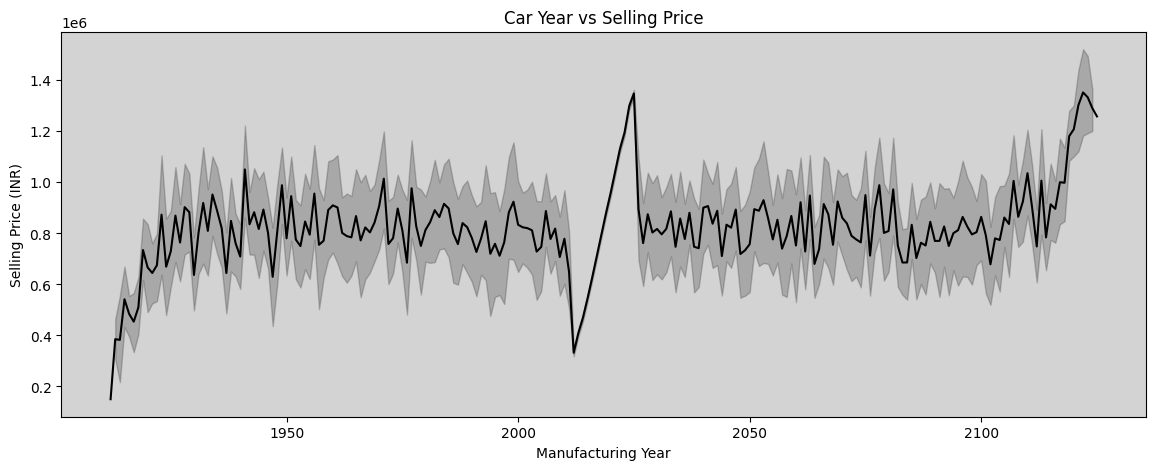

In [21]:
# Shows the relationship between manufacturing year and selling price.
plt.figure(figsize=(14, 5))
sns.lineplot(data=car,x="Year",y="Selling_Price_INR",color='k').axes.set_facecolor('lightgray')
plt.title("Car Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (INR)")
plt.show()

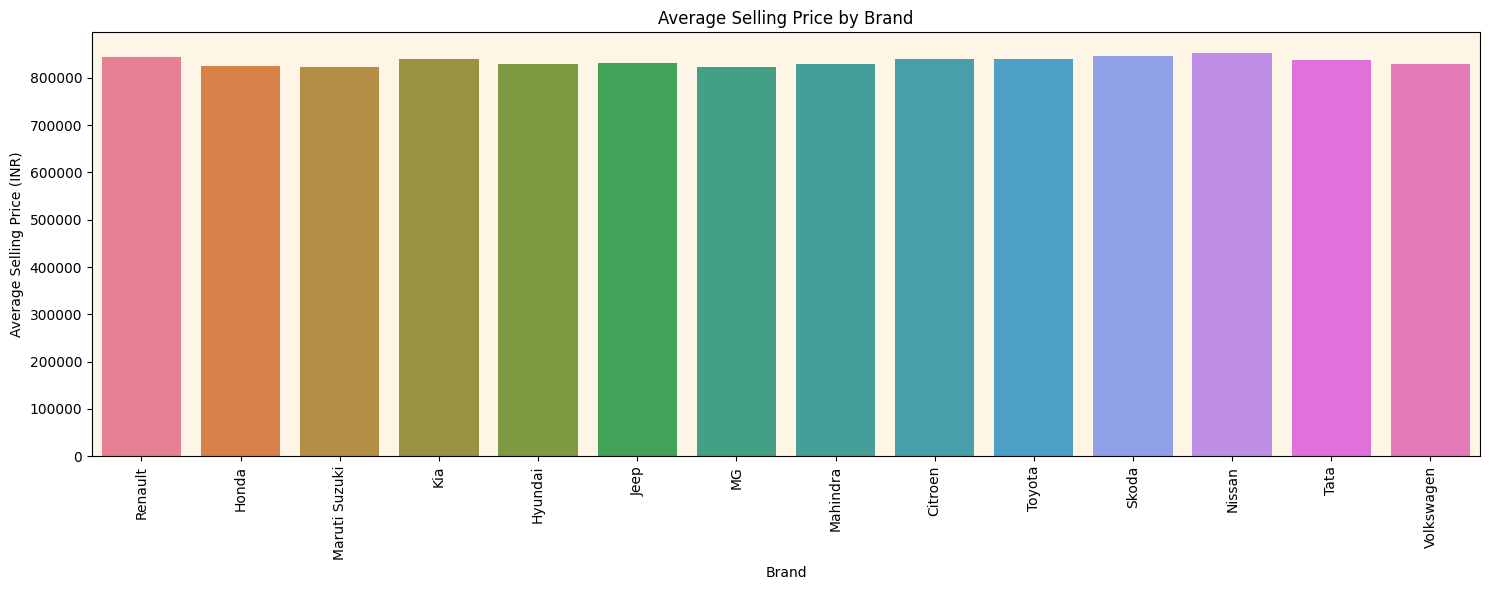

In [22]:
# Compares average selling prices across brands.
plt.figure(figsize=(15, 6))
sns.barplot(data=car,x="Brand",y="Selling_Price_INR",errorbar=None,hue="Brand").axes.set_facecolor('oldlace')
plt.title("Average Selling Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Selling Price (INR)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Engine CC vs Selling Price by Fuel Type**

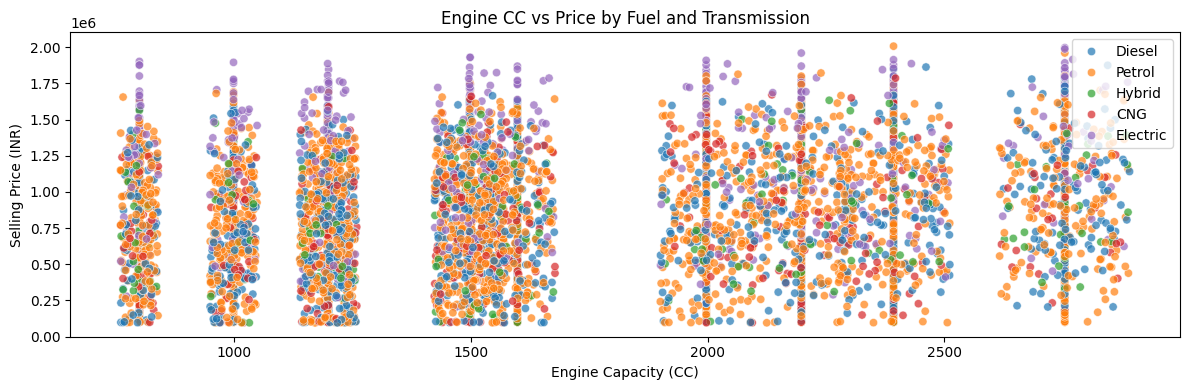

In [23]:
# Shows engine capacity versus selling price by fuel type.
plt.figure(figsize=(12, 4))
sns.scatterplot(data=car,x="Engine_CC",y="Selling_Price_INR",hue="Fuel_Type",alpha=0.7)
plt.title("Engine CC vs Price by Fuel and Transmission")
plt.xlabel("Engine Capacity (CC)")
plt.ylabel("Selling Price (INR)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


**Engine Capacity vs Selling Price**

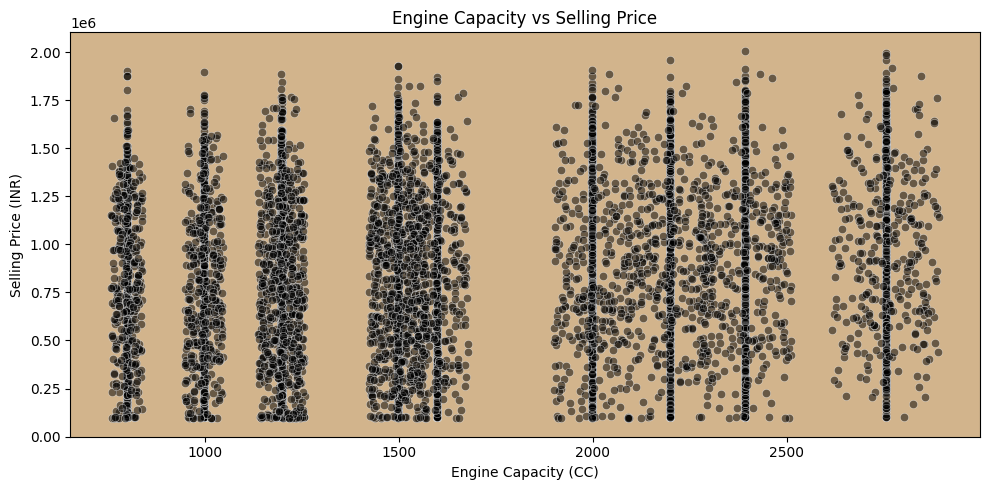

In [24]:
#Displays the relationship between engine capacity and selling price.
plt.figure(figsize=(10, 5))
sns.scatterplot(data=car,x="Engine_CC",y="Selling_Price_INR",color='k',alpha=0.5).axes.set_facecolor("tan")
plt.title("Engine Capacity vs Selling Price")
plt.xlabel("Engine Capacity (CC)")
plt.ylabel("Selling Price (INR)")
plt.tight_layout()
plt.show()


**Brand vs Selling Price by Fuel Type**

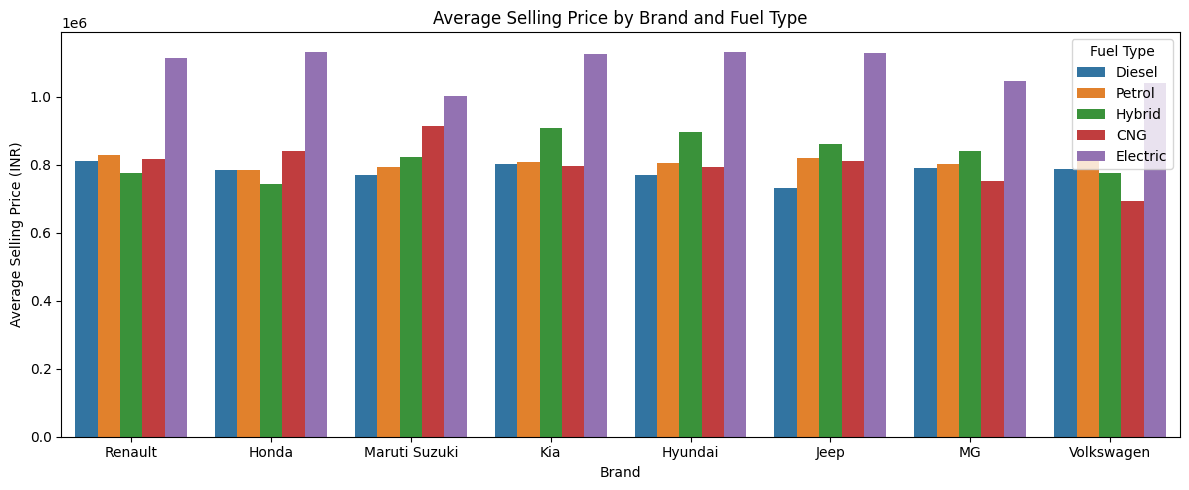

In [4]:
# Compares average selling prices by brand and fuel type.
top_brands = car["Brand"].value_counts().head(8).index
plot_df = car[car["Brand"].isin(top_brands)]
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df,x="Brand",y="Selling_Price_INR",hue="Fuel_Type",errorbar=None)
plt.title("Average Selling Price by Brand and Fuel Type")
plt.xlabel("Brand")
plt.ylabel("Average Selling Price (INR)")
plt.xticks(rotation=0)
plt.legend(title="Fuel Type")
plt.tight_layout()
plt.show()


# **Multivariate Analysis**

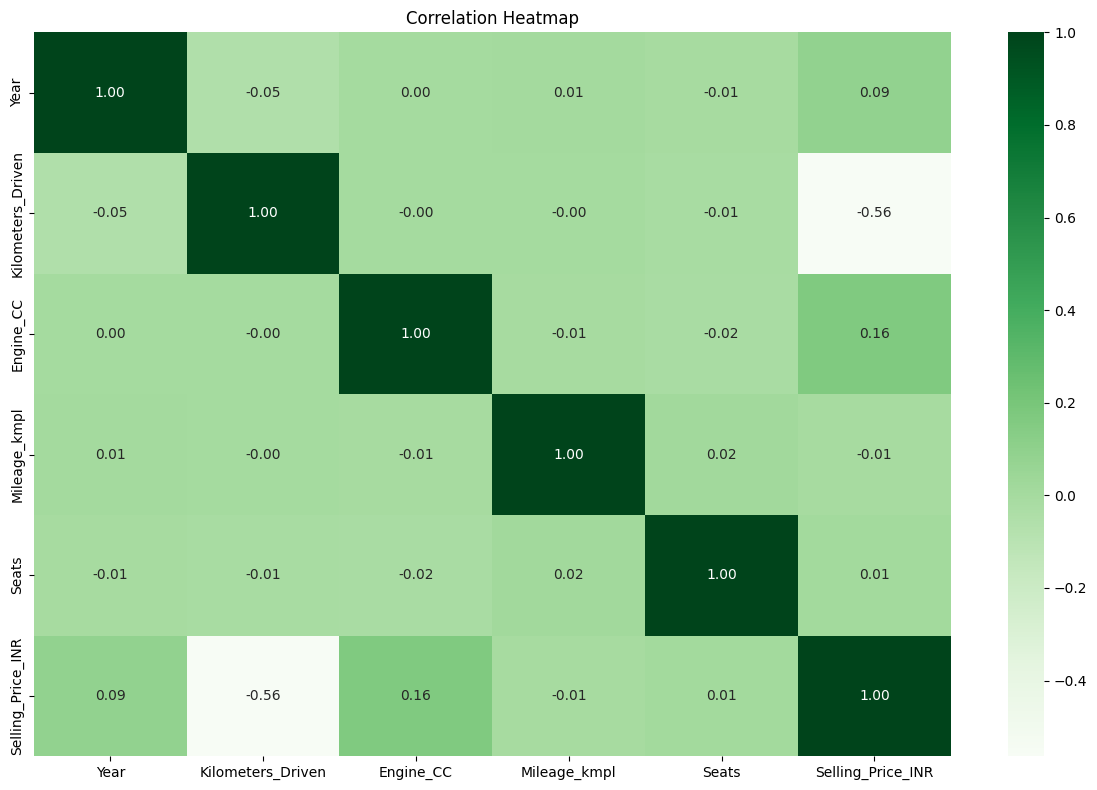

In [5]:
# 16. Displays correlations between numerical variable
numeric_df = car.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(),annot=True,cmap="Greens",fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


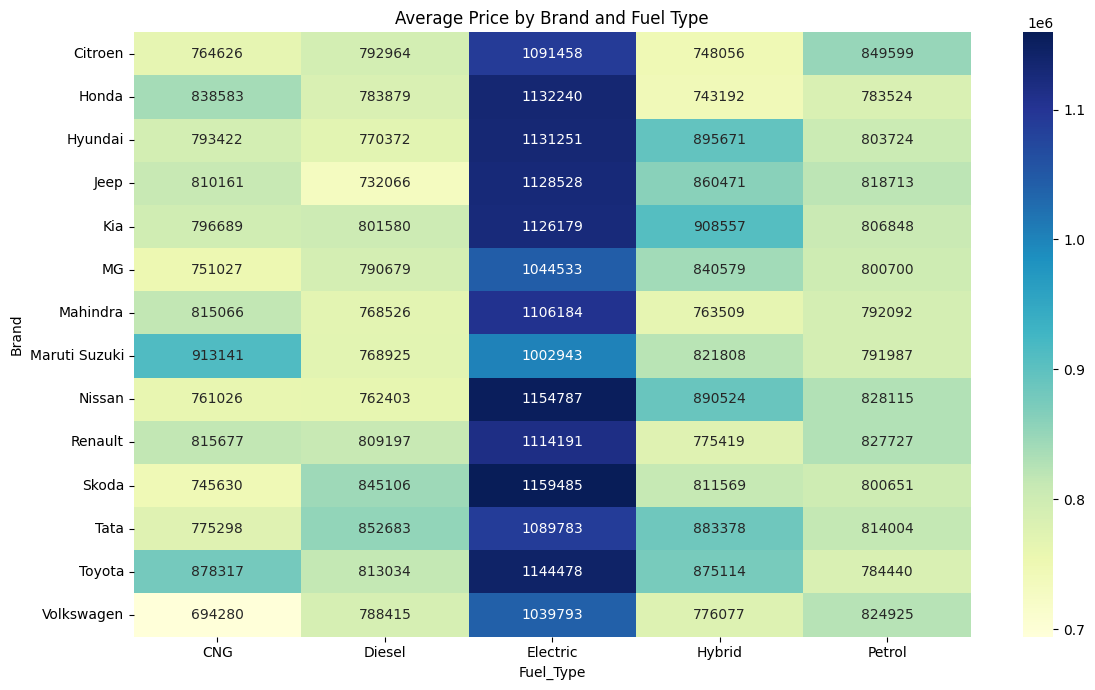

In [6]:
# Compares average selling prices by brand and fuel type using a heatmap.
brand_fuel = car.pivot_table(index="Brand",columns="Fuel_Type",values="Selling_Price_INR",aggfunc="mean")
plt.figure(figsize=(12, 7))
sns.heatmap(brand_fuel,annot=True,fmt=".0f",cmap="YlGnBu")
plt.title("Average Price by Brand and Fuel Type")
plt.tight_layout()
plt.show()

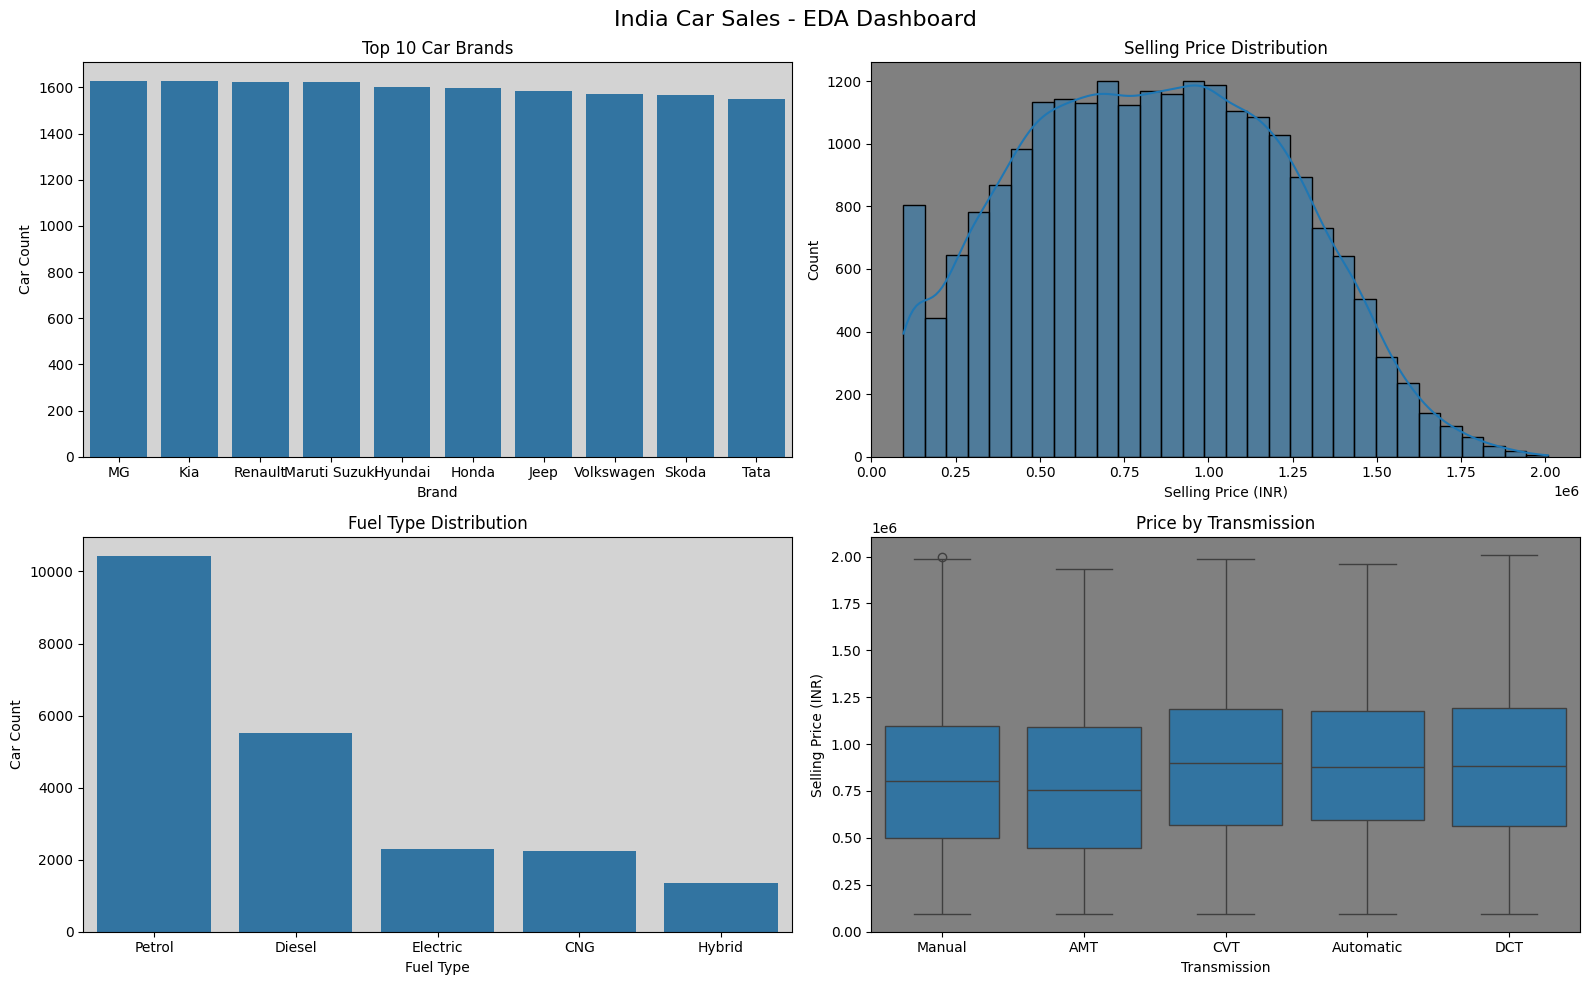

In [7]:
# Summarizes brand counts, price distribution, fuel types, and transmission prices.

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
# 1. Brand-wise car count
sns.countplot(data=car,x="Brand",order=car["Brand"].value_counts().index[:10],ax=axes[0, 0]).axes.set_facecolor("lightgray")
axes[0, 0].set_title("Top 10 Car Brands")
axes[0, 0].set_xlabel("Brand")
axes[0, 0].set_ylabel("Car Count")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Selling price distribution
sns.histplot(data=car,x="Selling_Price_INR",bins=30,kde=True,ax=axes[0, 1]).axes.set_facecolor("gray")
axes[0, 1].set_title("Selling Price Distribution")
axes[0, 1].set_xlabel("Selling Price (INR)")

# 3. Fuel type distribution
sns.countplot(data=car,x="Fuel_Type",order=car["Fuel_Type"].value_counts().index,ax=axes[1, 0]).axes.set_facecolor("lightgray")
axes[1, 0].set_title("Fuel Type Distribution")
axes[1, 0].set_xlabel("Fuel Type")
axes[1, 0].set_ylabel("Car Count")
axes[1, 0].tick_params(axis="x", rotation=0)

# 4. Selling price by transmission
sns.boxplot(data=car,x="Transmission",y="Selling_Price_INR",ax=axes[1, 1]).axes.set_facecolor("gray")
axes[1, 1].set_title("Price by Transmission")
axes[1, 1].set_xlabel("Transmission")
axes[1, 1].set_ylabel("Selling Price (INR)")
plt.suptitle("India Car Sales - EDA Dashboard", fontsize=16)
plt.tight_layout()
plt.show()


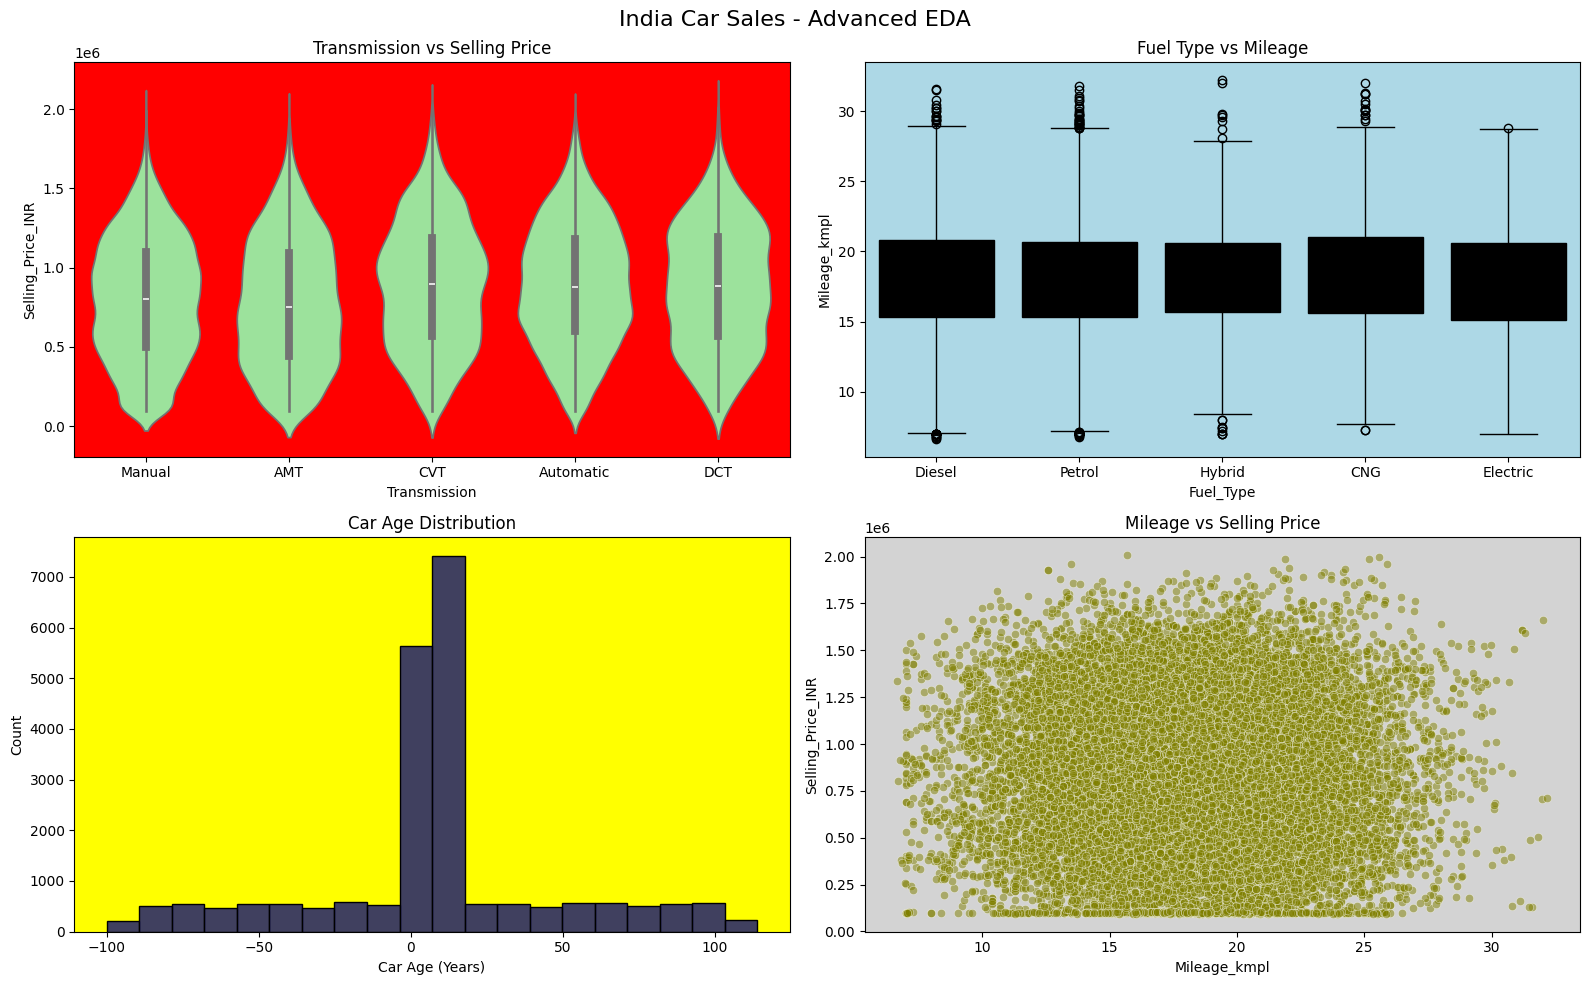

In [8]:
#Explores transmission prices, fuel-wise mileage, car age, and selling price.

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
# 1. Transmission vs Selling Price
sns.violinplot(data=car,x="Transmission",y="Selling_Price_INR",color='lightgreen',ax=axes[0, 0]).axes.set_facecolor("red")
axes[0, 0].set_title("Transmission vs Selling Price")

# 2. Fuel Type vs Mileage
sns.boxplot(data=car,x="Fuel_Type",y="Mileage_kmpl",color='k',ax=axes[0, 1]).axes.set_facecolor("lightblue")
axes[0, 1].set_title("Fuel Type vs Mileage")

# 3. Car Age Distribution
current_year = 2026
car_age = current_year - car["Year"]
sns.histplot(x=car_age,bins=20,color='navy',ax=axes[1, 0]).axes.set_facecolor("yellow")
axes[1, 0].set_title("Car Age Distribution")
axes[1, 0].set_xlabel("Car Age (Years)")

# 4. Mileage vs Selling Price
sns.scatterplot(data=car,x="Mileage_kmpl",y="Selling_Price_INR",color='olive',alpha=0.5,ax=axes[1, 1]).axes.set_facecolor("lightgray")
axes[1, 1].set_title("Mileage vs Selling Price")
plt.suptitle("India Car Sales - Advanced EDA", fontsize=16)
plt.tight_layout()
plt.show()


#**Feature Engineering**

**Car Age**

In [9]:
# Calculates the age of each car from its manufacturing year.
CURRENT_YEAR = 2026
car["Car_Age"] = CURRENT_YEAR - car["Year"]
print(car[["Year", "Car_Age"]].head())


   Year  Car_Age
0  2025        1
1  2014       12
2  2017        9
3  2024        2
4  2014       12


**Convert INR to Lakhs**

In [10]:
# Converts selling prices from rupees to lakhs.
car["Selling_Price_Lakh"] = (car["Selling_Price_INR"] / 100000)
print(car[["Selling_Price_INR", "Selling_Price_Lakh"]].head())


   Selling_Price_INR  Selling_Price_Lakh
0          1403457.0            14.03457
1           448389.0             4.48389
2           577683.0             5.77683
3          1542317.0            15.42317
4           120318.0             1.20318


**Create mileage categories**

In [11]:
# Groups mileage values into Low, Medium, High, and Very High categories.
car["Mileage_Category"] = pd.cut(
    car["Mileage_kmpl"],
    bins=[-np.inf, 10, 15, 20, np.inf],
    labels=["Low", "Medium", "High", "Very High"])

display(car[["Mileage_kmpl", "Mileage_Category"]].head())


,Mileage_kmpl,Mileage_Category
0,14.6,Medium
1,16.3,High
2,15.5,High
3,20.0,High
4,18.9,High


#**Data Visualization**

**Top 10 Brands**

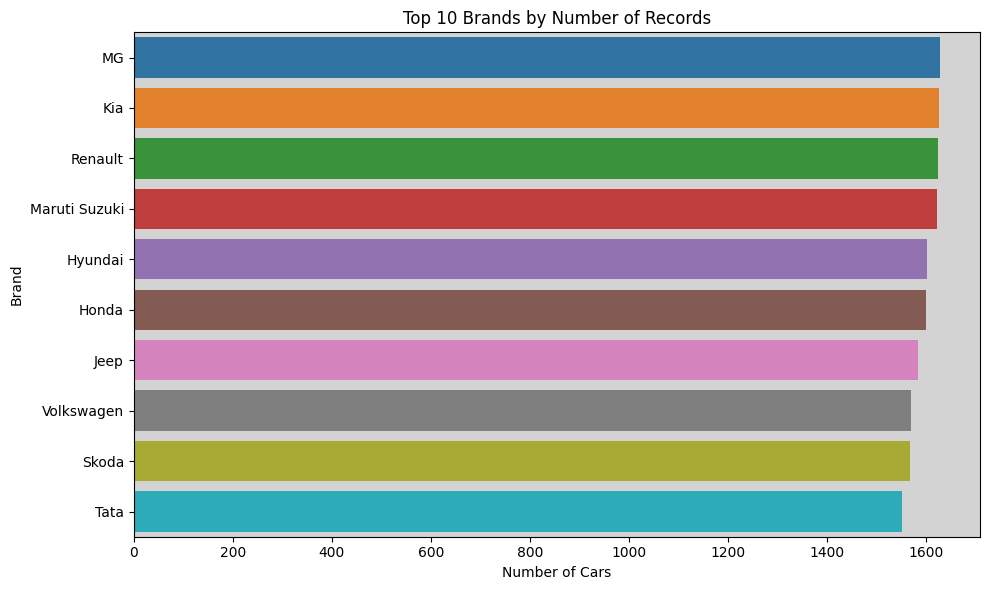

In [12]:
# Displays the top 10 brands by number of records.
top_brands = car["Brand"].value_counts().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_brands.values,y=top_brands.index,hue=top_brands.index).axes.set_facecolor("lightgray")
plt.title("Top 10 Brands by Number of Records")
plt.xlabel("Number of Cars")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()


**Transmission Distribution**

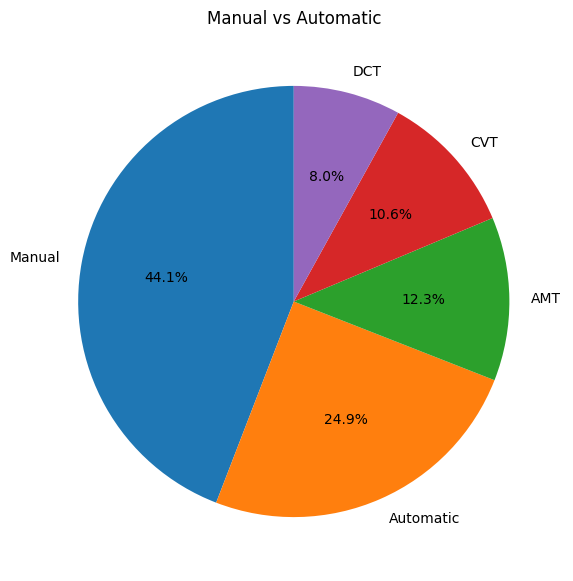

In [13]:
# Shows the percentage distribution of transmission types.
transmission_counts = car["Transmission"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(transmission_counts.values,labels=transmission_counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Manual vs Automatic")
plt.show()


#**Business Questions**

In [14]:
# Identifies the brand with the most records.
print("Brand with most records:")
print(car["Brand"].value_counts().head(1))


Brand with most records:
Brand
MG    1627
Name: count, dtype: int64


In [15]:
#  Displays the five brands with the highest average selling prices.
brand_avg_price = ( car.groupby("Brand")["Selling_Price_INR"].mean().sort_values(ascending=False))
display(brand_avg_price.head(5))


,Selling_Price_INR
Brand,
Nissan,851217.910368
Tata,850951.292680
Kia,848777.599796
Renault,848258.246771
Toyota,848039.579132


In [16]:
# Identifies the five cities with the most car records.
city_counts = car["City"].value_counts()
display(city_counts.head(5))


,count
City,
Mumbai,1567
Surat,1541
Lucknow,1505
Bhopal,1499
Kolkata,1492


In [17]:
# Identifies the most common fuel type.
fuel_counts = car["Fuel_Type"].value_counts()
print(fuel_counts)
print("Most common fuel type:", fuel_counts.idxmax())


Fuel_Type
Petrol      10427
Diesel       5516
Electric     2299
CNG          2228
Hybrid       1343
Name: count, dtype: int64
Most common fuel type: Petrol


In [18]:
# Measures the correlation between car age and selling price.
age_price_corr = car[["Car_Age", "Selling_Price_INR"]].corr().iloc[0, 1]
print("Car Age vs Selling Price Correlation:",round(age_price_corr, 3))


Car Age vs Selling Price Correlation: -0.088


In [19]:
car.to_csv("../data/clean_car_data.csv", index=False)

# Key Insights and Conclusion — India Car Sales EDA

Exploratory Data Analysis was performed on the India Car Sales dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

- **Brand Analysis:** Identified the brands with the highest number of records.
- **Price Analysis:** Used histograms and box plots to study selling price distributions and potential outliers.
- **Fuel Type Analysis:** Compared the frequency of different fuel types.
- **Transmission Analysis:** Used bar charts and a pie chart to understand transmission-type distribution.
- **Mileage Analysis:** Examined mileage distribution and potential outliers.
- **Price Comparison:** Compared selling prices by brand, fuel type, engine capacity, manufacturing year, and transmission.
- **Correlation Analysis:** Used a heatmap to examine relationships between numerical variables.
- **Feature Engineering:** Created car age, selling price in lakhs, and mileage categories.
- **Business Analysis:** Investigated brand counts, average brand prices, city-wise records, common fuel types, and car age versus selling price.


# Conclusion — India Car Sales EDA

Exploratory Data Analysis was performed on the India Car Sales dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The analysis included dataset inspection, data cleaning, missing-value handling, duplicate analysis, statistical analysis, univariate analysis, bivariate analysis, multivariate analysis, feature engineering, and data visualization.

The dataset was analyzed to understand car brands, selling prices, fuel types, transmission types, manufacturing years, mileage, and city-wise patterns.

The findings can help identify useful patterns in car pricing and customer preferences. These findings can also support business decisions related to inventory planning and pricing strategies.

The conclusions should be finalized using the actual results obtained from the dataset and visualizations.